<a href="https://colab.research.google.com/github/ryeggouti/morocco-world-cup-2022/blob/main/morocco_wc2022.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import warnings; warnings.filterwarnings("ignore")
!pip install statsbombpy -q
from statsbombpy import sb

comps = sb.competitions()
wc = comps[(comps.competition_name == "FIFA World Cup") & (comps.season_name == "2022")]
cid, sid = int(wc.competition_id.iloc[0]), int(wc.season_id.iloc[0])

matches = sb.matches(competition_id=cid, season_id=sid)
mar = matches[(matches.home_team == "Morocco") | (matches.away_team == "Morocco")]
print(mar[["match_date", "home_team", "away_team", "home_score", "away_score"]].sort_values("match_date"))


    match_date home_team away_team  home_score  away_score
7   2022-11-23   Morocco   Croatia           0           0
54  2022-11-27   Belgium   Morocco           0           2
0   2022-12-01    Canada   Morocco           1           2
46  2022-12-06   Morocco     Spain           0           0
36  2022-12-10   Morocco  Portugal           1           0
44  2022-12-14    France   Morocco           2           0
28  2022-12-17   Croatia   Morocco           2           1


   opponent  morocco_shots  opponent_shots
0   Croatia              8               5
1   Belgium             10              10
2    Canada              7               5
3     Spain              6              12
4  Portugal              9              12
5    France             13              14
6   Croatia              9              12


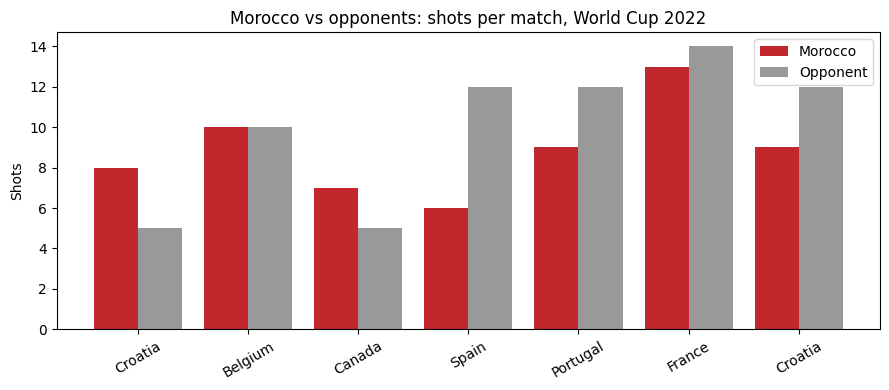

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

rows = []
for _, m in mar.sort_values("match_date").iterrows():
    ev = sb.events(match_id=m.match_id)
    shots = ev[(ev.type == "Shot") & (ev.period < 5)]
    opp = m.away_team if m.home_team == "Morocco" else m.home_team
    rows.append({
        "opponent": opp,
        "morocco_shots": (shots.team == "Morocco").sum(),
        "opponent_shots": (shots.team != "Morocco").sum(),
    })

df = pd.DataFrame(rows)
print(df)

x = range(len(df))
plt.figure(figsize=(9, 4))
plt.bar([i - 0.2 for i in x], df.morocco_shots, width=0.4, label="Morocco", color="#C1272D")
plt.bar([i + 0.2 for i in x], df.opponent_shots, width=0.4, label="Opponent", color="#999999")
plt.xticks(list(x), df.opponent, rotation=30)
plt.ylabel("Shots")
plt.title("Morocco vs opponents: shots per match, World Cup 2022")
plt.legend()
plt.tight_layout()
plt.show()
